In [77]:
import pandas as pd
import numpy as np
import os
from MultiAgent_DQ import *
import matplotlib.pyplot as plt

In [92]:
eps, lambda_b, alpha, delta, random_uniform, M_value = 0.1, 0.2,0.3,0.75,False,10
algo = Algorithm(
        e=eps, lambda_val=lambda_b, alpha=alpha, delta=delta,
        random_uniform=random_uniform, tolerance=1e-5, 
        M=int(M_value), verbose=False
    )
q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()    

In [121]:
q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[1]
q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[1]
                                                                


In [124]:
timeout_out, timeout_vi

({0: False,
  1: False,
  2: False,
  3: False,
  4: False,
  5: False,
  6: False,
  7: False,
  8: False,
  9: False},
 {0: False,
  1: False,
  2: False,
  3: False,
  4: False,
  5: False,
  6: False,
  7: False,
  8: False,
  9: False})

In [122]:
q1['StateC'] = q1['Q1'] - q1['Q3']
q1['StateD'] = q1['Q2'] - q1['Q4']
q2['StateC'] = q2['Q1'] - q2['Q3']
q2['StateD'] = q2['Q2'] - q2['Q4']

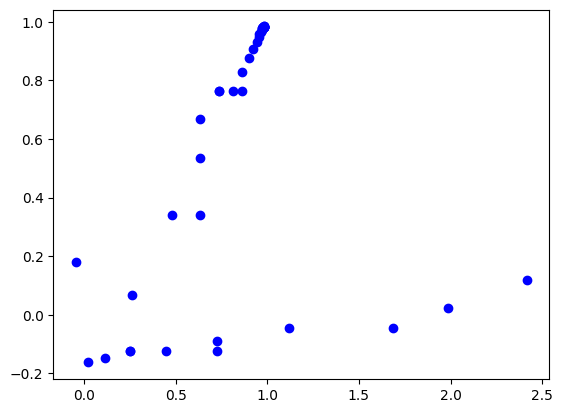

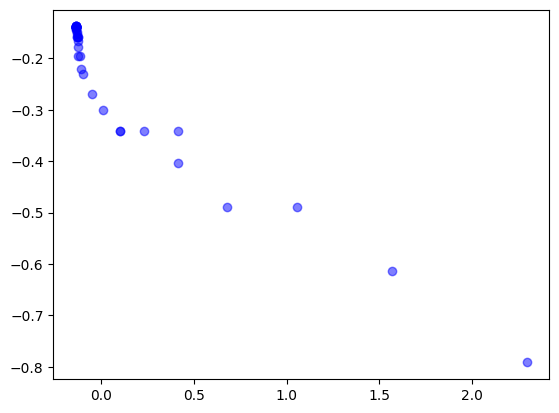

In [123]:
plt.scatter(q1['StateC'], q2['StateC'], label='Q1', color='blue', marker='o') #time order
plt.show()

plt.scatter(q1['StateD'], q2['StateD'], label='Q1', color='blue', alpha=0.5)
plt.show()


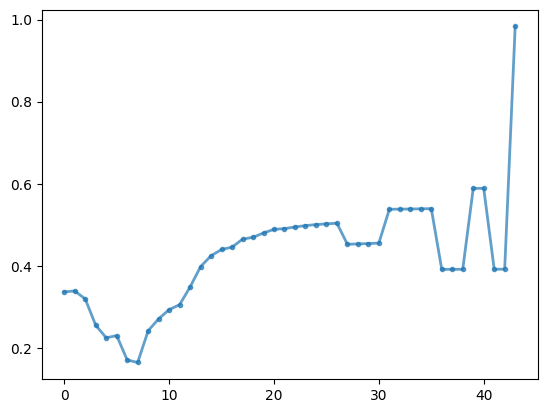

In [ ]:
plt.plot(q1['StateC'],  label=f"sample #", 
                marker=".", linewidth=2, alpha=0.7)

In [ ]:
last_1 = q1.iloc[-1]  # Get the last row using iloc
last_2 = q2.iloc[-1]
diff1 = last_1['Q1'] - last_2['Q1']
diff2 = last_1['Q2'] - last_2['Q2']
diff3 = last_1['Q3'] - last_2['Q3']
diff4 = last_1['Q4'] - last_2['Q4']

In [82]:
print('Diff 1:', diff1, 'Diff 2:', diff2, 
      'Diff 3:', diff3, 'Diff 4:', diff4)

Diff 1: 5.135950065571215e-06 Diff 2: 5.135950065571215e-06 Diff 3: 5.135950065571215e-06 Diff 4: 5.135950065571215e-06


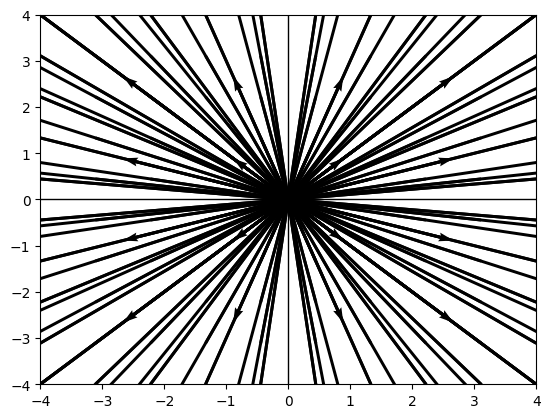

In [87]:
x_vals = np.linspace(-(1 / (1 - delta)), 1 / (1 - delta), 10)
y_vals = np.linspace(-(1 / (1 - delta)), 1 / (1 - delta), 10)
X, Y = np.meshgrid(x_vals, y_vals)

U = (diff1 - diff2 - X)
V = (diff3 - diff4- Y)

# Create the vector plot
fig, ax = plt.subplots()
ax.quiver(X, Y, U, V, angles='xy', scale_units='xy', scale=1/3, color='black')

# Set axis limits
ax.set_xlim([-(1 / (1 - delta)), 1 / (1 - delta)])
ax.set_ylim([-(1 / (1 - delta)), 1 / (1 - delta)])

# Add axes
ax.axhline(0, color='black',linewidth=1)
ax.axvline(0, color='black',linewidth=1)

# Display the plot
plt.show()
